<a href="https://colab.research.google.com/github/dechateau24/CalculMoyenneProjet/blob/main/projet_demarrage_online_retail_etudiant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet Data Mining : notebook de démarrage -- Online Retail II
**INSEEC Paris -- Data Mining / Data IA**

Ce notebook est **commun à toutes les missions**. Il vous amène du chargement des données jusqu'aux bases de travail prêtes à l'emploi :

| Étape | Contenu |
|---|---|
| 1 | Chargement du jeu de données |
| 2 | Exploration et repérage des problèmes |
| 3 | Nettoyage guidé, avec un journal de chaque étape |
| 4 | Choix du sous-ensemble (pays, période, produits) |
| 5 | Bases de travail par mission |

**Consigne** : remplacez chaque `____` par le code manquant, puis exécutez les cellules dans l'ordre.

**À retenir** : chaque filtrage change vos résultats. Vous devez pouvoir **justifier** chaque choix devant la classe. Le journal de nettoyage (étape 3) vous y aide.

In [ ]:
%pip install -q ucimlrepo openpyxl

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Chargement
Jeu de données **Online Retail II** (UCI, identifiant 502, licence CC BY 4.0) : transactions d'un site de vente en ligne britannique, décembre 2009 à décembre 2011.

**Option A** : chargement direct avec `ucimlrepo` (nécessite internet). Le chargement peut prendre un peu de temps.

In [ ]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=502)
d = dataset.data
df_brut = d.original.copy() if getattr(d, "original", None) is not None \
    else pd.concat([d.ids, d.features, d.targets], axis=1)

print(df_brut.shape)
df_brut.head()

DatasetNotFoundError: "Online Retail II" dataset (id=502) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true

In [ ]:
!wget -q -O online_retail.zip "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
!unzip -o online_retail.zip
!ls

Archive:  online_retail.zip
 extracting: online_retail_II.xlsx   
online_retail_II.xlsx  online_retail.zip  sample_data


In [ ]:
feuilles = pd.read_excel("online_retail_II.xlsx", sheet_name=None)
df_brut = pd.concat(feuilles.values(), ignore_index=True)
df_brut.to_csv("online_retail_II_brut.csv", index=False)
print(df_brut.shape)

(1067371, 8)


**Option B** (si l'option A échoue) : téléchargez le fichier sur la page UCI du jeu de données, placez `online_retail_II.xlsx` à côté du notebook, puis décommentez la cellule ci-dessous. Le fichier contient une feuille par période : on les concatène. La lecture est lente (plusieurs minutes), faites-la une seule fois puis sauvegardez en CSV.

In [ ]:
# feuilles = pd.read_excel("online_retail_II.xlsx", sheet_name=None)   # dictionnaire {feuille: tableau}
# df_brut = pd.concat(feuilles.values(), ignore_index=True)
# df_brut.to_csv("online_retail_II_brut.csv", index=False)             # pour la prochaine fois
# print(df_brut.shape)

### Harmonisation des noms de colonnes
Selon la source, les colonnes n'ont pas exactement le même nom (`Invoice` ou `InvoiceNo`, `Price` ou `UnitPrice`, `Customer ID` ou `CustomerID`). On les ramène à un nom unique : `Invoice, StockCode, Description, Quantity, InvoiceDate, Price, CustomerID, Country`.

In [ ]:
renommage = {"InvoiceNo": "Invoice", "UnitPrice": "Price", "Customer ID": "CustomerID"}
df = df_brut.rename(columns=renommage).copy()

attendues = ["Invoice", "StockCode", "Description", "Quantity",
             "InvoiceDate", "Price", "CustomerID", "Country"]
manquantes = [c for c in attendues if c not in df.columns]
assert not manquantes, f"Colonnes introuvables : {manquantes}. Colonnes presentes : {list(df.columns)}"

df = df[attendues]
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64")
df.dtypes

,0
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
Price,float64
CustomerID,Int64
Country,object


## 2. Exploration : repérer les problèmes
**Questions** (répondez dans une cellule texte) :
1. Combien de lignes, de factures, de clients, de produits, de pays ?
2. Quelles colonnes ont des valeurs manquantes, et quelle proportion ?
3. Que remarquez-vous dans les quantités et les prix minimaux ?

In [ ]:
print("Lignes   :", len(df))
print("Factures :", df["Invoice"].nunique())
print("Clients  :", df["CustomerID"].nunique())
print("Produits :", df["StockCode"].nunique())
print("Pays     :", df["Country"].nunique())
print("Periode  :", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())

print("\nValeurs manquantes (%) :")
print((df.isna().mean() * 100).round(1))

df[["Quantity", "Price"]].describe()

Lignes   : 1067371
Factures : 53628
Clients  : 5942
Produits : 5305
Pays     : 43
Periode  : 2009-12-01 07:45:00 -> 2011-12-09 12:50:00

Valeurs manquantes (%) :
Invoice        0.00
StockCode      0.00
Description    0.40
Quantity       0.00
InvoiceDate    0.00
Price          0.00
CustomerID    22.80
Country        0.00
dtype: float64


,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


In [ ]:
print("Top 5 pays :")
print(df["Country"].value_counts().head())

part_annul = df["Invoice"].str.startswith("C").mean() * 100
print(f"\nLignes appartenant a une facture annulee (numero commencant par C) : {part_annul:.1f} %")

Top 5 pays :
Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Name: count, dtype: int64

Lignes appartenant a une facture annulee (numero commencant par C) : 1.8 %


## 3. Nettoyage guidé
Chaque étape est consignée dans un **journal** : nombre de lignes avant et après. Ce journal sera précieux pour votre diapo « Données et nettoyage ».

**Choix important** : les annulations ne sont pas jetées, elles sont mises de côté (`df_annul`), car la mission *Retours et annulations* en a besoin.

In [ ]:
journal = []

def consigner(etape, avant, apres):
    journal.append({"etape": etape, "avant": avant, "apres": apres, "supprimees": avant - apres})

**Étape 3.1** -- Séparer les annulations des ventes.

In [ ]:
est_annulation = df["Invoice"].str.startswith("C")

df_annul = df[est_annulation].copy()
df_ventes = df[~est_annulation].copy()
consigner("Annulations mises de cote", len(df), len(df_ventes))
print(len(df_annul), "lignes d'annulation,", len(df_ventes), "lignes de vente")

19494 lignes d'annulation, 1047877 lignes de vente


**Étape 3.2** -- Retirer les lignes de vente aberrantes : quantité ou prix qui ne sont pas strictement positifs (ajustements, cadeaux, erreurs).

In [ ]:
avant = len(df_ventes)
df_ventes = df_ventes[(df_ventes["Quantity"] > 0) & (df_ventes["Price"] > 0)]
consigner("Quantite ou prix non positifs", avant, len(df_ventes))

**Étape 3.3** -- Ne garder que les **vrais produits**. Les codes produits « normaux » commencent par 5 chiffres (par exemple `85123A`). Les autres (frais de port, frais bancaires, échantillons, ajustements...) ne sont pas des produits.

*Question* : listez quelques codes retirés. Que représentent-ils ?

In [ ]:
avant = len(df_ventes)
est_produit = df_ventes["StockCode"].str.match(r"^\d{5}")

print("Exemples de codes retires :", df_ventes.loc[~est_produit, "StockCode"].unique()[:15])

df_ventes = df_ventes[est_produit]
consigner("Codes non produits", avant, len(df_ventes))

Exemples de codes retires : ['POST' 'DCGS0058' 'DCGS0068' 'DOT' 'M' 'DCGS0004' 'DCGS0076' 'C2'
 'BANK CHARGES' 'DCGS0003' 'TEST001' 'DCGS0072' 'gift_0001_80'
 'gift_0001_20' 'DCGS0044']


**Étape 3.4** -- Supprimer les doublons exacts, puis calculer le montant de chaque ligne.

In [ ]:
avant = len(df_ventes)
df_ventes = df_ventes.drop_duplicates()
consigner("Doublons exacts", avant, len(df_ventes))

df_ventes["Montant"] = df_ventes["Quantity"] * df_ventes["Price"]

**Étape 3.5** -- Les annulations subissent le même filtre « vrais produits », et on prépare un dictionnaire code → description lisible (un même code peut avoir plusieurs descriptions : on garde la plus fréquente).

In [ ]:
df_annul = df_annul[df_annul["StockCode"].str.match(r"^\d{5}")].copy()
df_annul["Quantite_annulee"] = df_annul["Quantity"].abs()

def description_courante(s):
    m = s.dropna().mode()
    return m.iat[0] if len(m) else ""

noms = df_ventes.groupby("StockCode")["Description"].agg(description_courante)

df_clean = df_ventes.reset_index(drop=True)
print(len(df_clean), "lignes de ventes propres,", len(df_annul), "lignes d'annulation de produits")
pd.DataFrame(journal)

1003214 lignes de ventes propres, 18285 lignes d'annulation de produits


,etape,avant,apres,supprimees
0,Annulations mises de cote,1067371,1047877,19494
1,Quantite ou prix non positifs,1047877,1041670,6207
2,Codes non produits,1041670,1036877,4793
3,Doublons exacts,1036877,1003214,33663


### Clients sans identifiant
Une partie des lignes n'a pas de `CustomerID`. Ce n'est pas un défaut pour toutes les missions :

| Mission | Besoin de `CustomerID` ? |
|---|---|
| A Cross-selling, D Promotions, F Retours | Non : on raisonne par facture ou par produit |
| B Segmentation, C Recommandation, E Parcours | **Oui** : on raisonne par client |

On garde donc deux versions des données.

In [ ]:
df_clients = df_clean.dropna(subset=["CustomerID"]).copy()
print(f"{len(df_clients) / len(df_clean) * 100:.1f} % des lignes ont un identifiant client")

77.4 % des lignes ont un identifiant client


In [ ]:
DATE_COUPURE = "2010-11-01"   # apprentissage avant, test à partir de cette date

d = df_clients_sub[df_clients_sub["StockCode"].isin(top)]
train = d[d["InvoiceDate"] < DATE_COUPURE]
test = d[d["InvoiceDate"] >= DATE_COUPURE]

M_train = (train.assign(v=1)
                .pivot_table(index="CustomerID", columns="StockCode",
                             values="v", aggfunc="max", fill_value=0))

n_cl, n_pr = M_train.shape
print("Matrice d'apprentissage :", M_train.shape)
print("Densité :", round(M_train.values.sum() / (n_cl * n_pr) * 100, 2), "% de cases à 1")

# clients évaluables : au moins 5 produits en apprentissage
# et au moins 1 produit NOUVEAU (jamais acheté avant) dans la période de test
achats_train = train.groupby("CustomerID")["StockCode"].apply(set)
achats_test = test.groupby("CustomerID")["StockCode"].apply(set)

nouveaux = {}
for c in achats_test.index.intersection(achats_train.index):
    nv = achats_test[c] - achats_train[c]
    if len(nv) > 0 and len(achats_train[c]) >= 5:
        nouveaux[c] = nv

print("Lignes train / test :", len(train), "/", len(test))
print("Clients évaluables :", len(nouveaux))
print("Médiane de produits nouveaux par client (test) :", np.median([len(s) for s in nouveaux.values()]))

Matrice d'apprentissage : (3426, 999)
Densité : 4.06 % de cases à 1
Lignes train / test : 204334 / 59561
Clients évaluables : 1252
Médiane de produits nouveaux par client (test) : 11.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

produits = M_train.columns
sim = cosine_similarity(M_train.T.values)
np.fill_diagonal(sim, 0)
sim = pd.DataFrame(sim, index=produits, columns=produits)

popularite = M_train.sum()   # nombre de clients ayant acheté chaque produit

def recommander(client, k=10, methode="cosinus"):
    ligne = M_train.loc[client]
    possedes = ligne[ligne == 1].index
    if methode == "cosinus":
        scores = sim[possedes].sum(axis=1)   # somme des similarités avec les produits déjà achetés
    else:
        scores = popularite.copy()           # référence : les produits les plus populaires
    scores = scores.drop(possedes)           # on ne recommande que des produits non achetés
    return scores.nlargest(k).index.tolist()

def evaluer(k, methode):
    prec, rapp, hit = [], [], []
    for c, vrais in nouveaux.items():
        vrais = vrais & set(produits)
        if not vrais:
            continue
        reco = recommander(c, k, methode)
        bons = len(set(reco) & vrais)
        prec.append(bons / k)
        rapp.append(bons / len(vrais))
        hit.append(bons > 0)
    return np.mean(prec), np.mean(rapp), np.mean(hit)

resultats = []
for k in [5, 10, 20]:
    for methode in ["populaires", "cosinus"]:
        p, r, h = evaluer(k, methode)
        resultats.append({"k": k, "méthode": methode, "précision@k": round(p, 3),
                          "rappel@k": round(r, 3), "au moins 1 bon": round(h, 3)})
pd.DataFrame(resultats)

,k,méthode,précision@k,rappel@k,au moins 1 bon
0,5,populaires,0.04,0.01,0.18
1,5,cosinus,0.08,0.03,0.28
2,10,populaires,0.04,0.03,0.30
3,10,cosinus,0.07,0.05,0.39
4,20,populaires,0.04,0.05,0.43
5,20,cosinus,0.06,0.09,0.53


In [ ]:
client_ex = list(nouveaux.keys())[0]
print("Client", client_ex, "- a déjà acheté", int(M_train.loc[client_ex].sum()), "produits")
print("\nRecommandations (cosinus) :")
for code in recommander(client_ex, 5):
    print(" -", noms.get(code, code))
print("\nProduits réellement achetés ensuite (parmi les nouveaux) :")
for code in list(nouveaux[client_ex])[:5]:
    print(" -", noms.get(code, code))

Client 12747 - a déjà acheté 46 produits

Recommandations (cosinus) :
 - LOVE BUILDING BLOCK WORD
 - HEART OF WICKER SMALL
 - BATHROOM METAL SIGN
 - REGENCY CAKESTAND 3 TIER
 - LUNCH BAG RED RETROSPOT

Produits réellement achetés ensuite (parmi les nouveaux) :
 - SWEETHEART RECIPE BOOK STAND
 - WELCOME  WOODEN BLOCK LETTERS


In [ ]:
sim_cl = cosine_similarity(M_train.values)
np.fill_diagonal(sim_cl, 0)
sim_cl = pd.DataFrame(sim_cl, index=M_train.index, columns=M_train.index)

def recommander_clients(client, k=10, voisins=30):
    s = sim_cl[client].nlargest(voisins)
    scores = M_train.loc[s.index].mul(s, axis=0).sum(axis=0)
    possedes = M_train.loc[client][M_train.loc[client] == 1].index
    return scores.drop(possedes).nlargest(k).index.tolist()

def evaluer_fn(fonction, k):
    prec, rapp, hit = [], [], []
    for c, vrais in nouveaux.items():
        vrais = vrais & set(produits)
        if not vrais:
            continue
        reco = fonction(c, k)
        bons = len(set(reco) & vrais)
        prec.append(bons / k); rapp.append(bons / len(vrais)); hit.append(bons > 0)
    return np.mean(prec), np.mean(rapp), np.mean(hit)

res2 = []
for k in [5, 10, 20]:
    for nom, f in [("produits (cosinus)", lambda c, k: recommander(c, k, "cosinus")),
                   ("clients (cosinus)", recommander_clients)]:
        p, r, h = evaluer_fn(f, k)
        res2.append({"k": k, "méthode": nom, "précision@k": round(p, 3),
                     "rappel@k": round(r, 3), "au moins 1 bon": round(h, 3)})
pd.DataFrame(res2)

,k,méthode,précision@k,rappel@k,au moins 1 bon
0,5,produits (cosinus),0.08,0.03,0.28
1,5,clients (cosinus),0.09,0.04,0.30
2,10,produits (cosinus),0.07,0.05,0.39
3,10,clients (cosinus),0.07,0.06,0.43
4,20,produits (cosinus),0.06,0.09,0.53
5,20,clients (cosinus),0.06,0.10,0.56


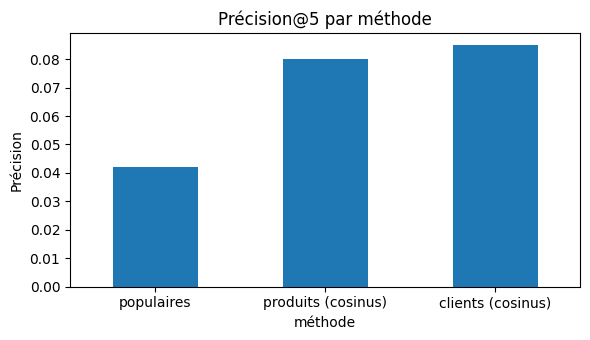

In [ ]:
t1 = pd.DataFrame(resultats)
t2 = pd.DataFrame(res2)

tout = pd.concat([t1, t2])
tout["méthode"] = tout["méthode"].replace({"cosinus": "produits (cosinus)"})
tout = tout[tout["k"] == 5].drop_duplicates("méthode")

ax = tout.set_index("méthode")["précision@k"].plot(kind="bar", figsize=(6, 3.5), rot=0,
                                                   title="Précision@5 par méthode")
ax.set_ylabel("Précision")
plt.tight_layout()
plt.show()

**Questions de synthèse du nettoyage** :
- Quelle étape supprime le plus de lignes ? Pourquoi ?
- Un de ces choix pourrait-il biaiser votre mission ? Lequel ?

## 4. Choix du sous-ensemble
Le jeu complet est trop volumineux pour Apriori, K-Means sur tous les produits, ou une matrice client × produit complète. **Choisissez et justifiez** votre périmètre.

Paramètres à adapter à votre mission :

In [ ]:
PAYS = "United Kingdom"        # un pays, ou None pour tous les pays
DATE_DEBUT = "2010-01-01"      # incluse
DATE_FIN = "2011-01-01"        # exclue
TOP_PRODUITS = 1000           # nombre de produits les plus frequents conserves

In [ ]:
def sous_ensemble(table):
    masque = (table["InvoiceDate"] >= DATE_DEBUT) & (table["InvoiceDate"] < DATE_FIN)
    if PAYS is not None:
        masque &= table["Country"] == PAYS
    return table[masque]

df_sub = sous_ensemble(df_clean)
df_clients_sub = sous_ensemble(df_clients)
df_annul_sub = sous_ensemble(df_annul)

# produits les plus frequents : ceux presents dans le plus de factures
top = df_sub.groupby("StockCode")["Invoice"].nunique().nlargest(TOP_PRODUITS).index
df_top = df_sub[df_sub["StockCode"].isin(top)]

print("Lignes de ventes du sous-ensemble :", len(df_sub))
print("Factures :", df_sub["Invoice"].nunique(), "| Clients :", df_clients_sub["CustomerID"].nunique())
print("Part des lignes conservees avec les", TOP_PRODUITS, "produits :", round(len(df_top) / len(df_sub) * 100, 1), "%")

Lignes de ventes du sous-ensemble : 442125
Factures : 18140 | Clients : 3870
Part des lignes conservees avec les 1000 produits : 74.0 %


**Premier regard descriptif** : chiffre d'affaires mensuel du sous-ensemble.

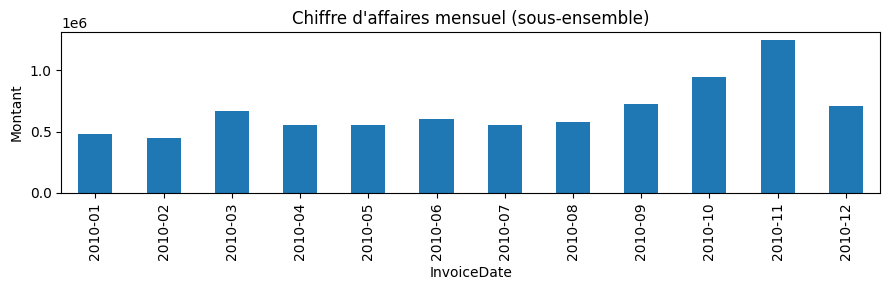

In [ ]:
ca_mensuel = df_sub.groupby(df_sub["InvoiceDate"].dt.to_period("M"))["Montant"].sum()
ca_mensuel.plot(kind="bar", figsize=(9, 3), title="Chiffre d'affaires mensuel (sous-ensemble)")
plt.ylabel("Montant")
plt.tight_layout()
plt.show()

In [ ]:
for n in [200, 500, 1000, 2000]:
    top_n = df_sub.groupby("StockCode")["Invoice"].nunique().nlargest(n).index
    d = df_clients_sub[df_clients_sub["StockCode"].isin(top_n)]
    par_client = d.groupby("CustomerID")["StockCode"].nunique()
    print(n, "produits |", round(len(d) / len(df_clients_sub) * 100, 1), "% des lignes |",
          len(par_client), "clients | médiane produits/client :", par_client.median(),
          "| clients avec >= 5 produits :", (par_client >= 5).sum())

200 produits | 33.0 % des lignes | 3663 clients | médiane produits/client : 11.0 | clients avec >= 5 produits : 2847
500 produits | 55.8 % des lignes | 3765 clients | médiane produits/client : 20.0 | clients avec >= 5 produits : 3324
1000 produits | 76.3 % des lignes | 3817 clients | médiane produits/client : 28.0 | clients avec >= 5 produits : 3498
2000 produits | 93.2 % des lignes | 3851 clients | médiane produits/client : 35.0 | clients avec >= 5 produits : 3587


## 5. Bases de travail par mission
Utilisez uniquement la section de **votre mission** ; les autres sont données pour information.

### Missions A et D : paniers (une facture = un panier)

In [ ]:
# Matrice facture x produit (booleenne), prete pour un algorithme de type Apriori
panier_bool = (
    df_top.assign(v=1)
          .pivot_table(index="Invoice", columns="StockCode", values="v", aggfunc="max", fill_value=0)
          .astype(bool)
)
print(panier_bool.shape)

# Pour lire les resultats : remplacer les codes par les descriptions
def lire(codes):
    return [noms.get(c, c) for c in codes]

### Mission B : segmentation (tableau RFM par client)
- **R**écence : jours depuis le dernier achat.
- **F**réquence : nombre de factures.
- **M**ontant : somme dépensée.

In [ ]:
date_ref = df_clients_sub["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_clients_sub.groupby("CustomerID").agg(
    DernierAchat=("InvoiceDate", "____"),
    Frequence=("Invoice", "____"),
    Montant=("Montant", "____"),
)
rfm["Recence"] = (date_ref - rfm["DernierAchat"]).dt.days
rfm = rfm[["Recence", "Frequence", "Montant"]]
rfm.describe()

*À faire avant K-Means* : regardez l'asymétrie de `Frequence` et `Montant` (quelques gros clients), pensez à la **standardisation** et réfléchissez à l'effet des valeurs extrêmes (séance clustering).

### Mission C : recommandation (matrice client × produit)

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

df_top_clients = df_clients_sub[df_clients_sub["StockCode"].isin(top)]
matrice = (
    df_top_clients.assign(v=1)
                  .pivot_table(index="CustomerID", columns="StockCode", values="v", aggfunc="max", fill_value=0)
)

# similarite cosinus entre produits (colonnes)
sim = pd.DataFrame(cosine_similarity(matrice.T), index=matrice.columns, columns=matrice.columns)

exemple = matrice.columns[0]
proches = sim[exemple].drop(exemple).nlargest(5)
print("Produit :", noms.get(exemple, exemple))
for code_p, s in proches.items():
    print(f"  {s:.2f}  {noms.get(code_p, code_p)}")

Produit : INFLATABLE POLITICAL GLOBE 
  0.19  SKULLS  WATER TRANSFER TATTOOS 
  0.18  BLUE HARMONICA IN BOX 
  0.18  PACK OF 6 SANDCASTLE FLAGS ASSORTED
  0.18  LUNCH BAG WOODLAND
  0.18  LUNCH BAG  BLACK SKULL.


### Mission E : parcours clients (séquences)
**Choix à justifier** : une facture contient plusieurs produits au même instant, donc leur ordre est indéterminé. On représente ici chaque facture par son **article principal** (celui de plus grand montant). D'autres choix sont possibles (catégorie, mois d'achat...).

In [ ]:
idx = df_clients_sub.groupby("Invoice")["Montant"].idxmax()
factures = (
    df_clients_sub.loc[idx, ["CustomerID", "Invoice", "InvoiceDate", "StockCode"]]
                  .sort_values(["CustomerID", "InvoiceDate", "Invoice"])
)
factures["delai_jours"] = factures.groupby("CustomerID")["InvoiceDate"].diff().dt.days

sequences_clients = factures.groupby("CustomerID")["StockCode"].apply(list)
print("Clients avec au moins 2 factures :", (sequences_clients.str.len() >= 2).sum())
print("Delai median entre deux achats (jours) :", factures["delai_jours"].median())
sequences_clients.head()

Clients avec au moins 2 factures : 2581
Delai median entre deux achats (jours) : 20.0


,StockCode
CustomerID,
12346,"[20679, 21524]"
12608,[84879]
12745,"[22649, 22649]"
12746,[21845]
12747,"[46000S, 85124A, 84469, 82484, 82484, 21624, 2..."


Vous pouvez réutiliser `est_sous_sequence`, `support` et `distance_edition` du notebook de la séance 4 sur `sequences_clients.tolist()`.

### Mission F : retours et annulations

In [ ]:
qte_vendue = df_sub.groupby("StockCode")["Quantity"].sum()
qte_annulee = df_annul_sub.groupby("StockCode")["Quantite_annulee"].sum()

taux = pd.DataFrame({"vendue": qte_vendue, "annulee": qte_annulee}).fillna(0)
taux["taux_annulation"] = taux["annulee"] / taux["vendue"]

# attention aux petits effectifs : un taux eleve sur 3 articles vendus n'est pas fiable
fiables = taux[taux["vendue"] >= 100].sort_values("taux_annulation", ascending=False)
fiables.head(10).assign(nom=lambda t: [noms.get(c, c) for c in t.index])

## 6. Sauvegarde (optionnelle)
Sauvegardez vos bases nettoyées pour ne pas tout recalculer.

In [1]:
df_clean.to_csv("online_retail_II_propre.csv", index=False)
print("Sauvegarde effectuee")

NameError: name 'df_clean' is not defined

## Pour la suite
Chaque groupe poursuit dans **son propre notebook** à partir de la base correspondant à sa mission, puis prépare le PowerPoint de soutenance :
question métier → données et nettoyage → méthode → résultats → conclusion data mining → limites → décisions métier.